In [1]:
!pip install pillow numpy matplotlib opencv-python

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [4]:
img1 = Image.open("image1.jpg").convert("RGB")
img2 = Image.open("image2.jpg").convert("RGB")

print("image 1 size:", img1.size)
print("image 2 size:", img2.size)

image 1 size: (3200, 4000)
image 2 size: (4000, 4000)


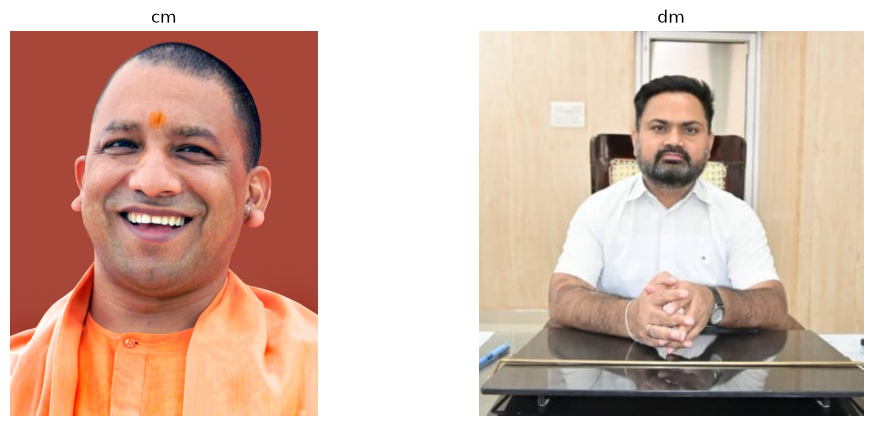

In [5]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img1)
plt.title("cm")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2)
plt.title("dm")
plt.axis("off")

plt.show()

In [6]:
width = 1280
height = 720

img1 = img1.resize((width, height))
img2 = img2.resize((width, height))

img1_np = np.array(img1)
img2_np = np.array(img2)

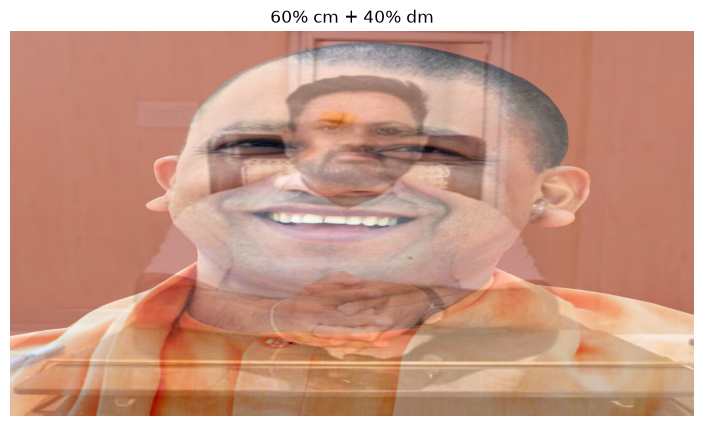

In [7]:
blended = cv2.addWeighted(
    img1_np, 0.6,
    img2_np, 0.4,
    0
)

plt.figure(figsize=(10, 5))
plt.imshow(blended)
plt.title("60% cm + 40% dm")
plt.axis("off")
plt.show()

In [8]:
cv2.imwrite(
    "blended_image.jpg",
    cv2.cvtColor(blended, cv2.COLOR_RGB2BGR)
)

print("Blended image saved successfully!")

Blended image saved successfully!


In [9]:
def zoom_image(image, zoom_factor):
    h, w = image.shape[:2]

    new_h = int(h / zoom_factor)
    new_w = int(w / zoom_factor)

    y1 = (h - new_h) // 2
    x1 = (w - new_w) // 2

    cropped = image[y1:y1 + new_h, x1:x1 + new_w]

    zoomed = cv2.resize(cropped, (w, h))

    return zoomed

In [10]:
def cross_dissolve(image1, image2, alpha):
    return cv2.addWeighted(
        image1, 1 - alpha,
        image2, alpha,
        0
    )

In [11]:
fps = 30
duration = 3
total_frames = fps * duration

video_path = "image_blending_video.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    video_path,
    fourcc,
    fps,
    (width, height)
)

transition_frames = 6  # 0.2 seconds

In [12]:
for frame_num in range(total_frames):

    t = frame_num / fps

    # Scene 1: cm (0–1 second)
    if t < 1.0 - transition_frames / fps:

        progress = t / 1.0

        zoom_factor = 1.0 + 0.04 * progress

        frame = zoom_image(img1_np, zoom_factor)

    # Transition 1: cm to dm
    elif t < 1.0:

        alpha = (t - (1.0 - transition_frames / fps)) / (transition_frames / fps)

        frame = cross_dissolve(img1_np, img2_np, alpha)

    # Scene 2: dm (1–2 seconds)
    elif t < 2.0 - transition_frames / fps:

        progress = t - 1.0

        zoom_factor = 1.0 + 0.03 * progress

        frame = zoom_image(img2_np, zoom_factor)

    # Transition 2: dm to blended image
    elif t < 2.0:

        alpha = (t - (2.0 - transition_frames / fps)) / (transition_frames / fps)

        frame = cross_dissolve(img2_np, blended, alpha)

    # Scene 3: Final blended image (2–3 seconds)
    else:

        frame = blended.copy()

    # Convert RGB to BGR for OpenCV
    frame_bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)

    out.write(frame_bgr)

out.release()

print("Video created successfully:", video_path)

Video created successfully: image_blending_video.mp4


In [13]:
from IPython.display import Video, display

display(Video("image_blending_video.mp4", embed=True))